# Moroccan Crop Classification: does a quantum kernel add anything beyond a matched classical model?

**Question.** On the supplied 914 / 150 / 221 field split, does a fidelity **quantum-kernel SVM** contribute beyond a **classical RBF-SVM on the same inputs and preprocessing**? Secondary questions: does circuit depth matter, and do the models behave differently with less training data?

**Scope, stated honestly**
- All quantum computation is **exact classical statevector simulation** (Qiskit `Statevector`, at most 8 qubits). No noise model, no IBM hardware was used for any number in this notebook.
- **Validation** (150 fields) is used for hyperparameter selection and for every comparison, so validation scores are optimistic for every model alike.
- The **test set has no labels**. We only write test *predictions*; no test score is computed or used for selection.
- Preprocessing and every learned transformation are fitted on **training fields only**. IDs are never model inputs.

**How to run:** select the *Crop challenge* kernel (Python 3.12, `pip install -r requirements.txt`) and **Run All** from the `notebooks/` folder. Expected total time: roughly 5 to 15 minutes (the sweep dominates). Everything is written to `outputs/`.

In [1]:
import json, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'challenge').exists(): ROOT = ROOT.parent
assert (ROOT / 'challenge').exists(), 'Run this notebook from the repository (notebooks/ folder)'
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'experiments'))
FIG = ROOT / 'outputs' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
LABELS = ['alfalfa', 'maize', 'wheat']
from challenge.data import load_data            # verifies dataset checksums and split IDs
tables, _, _, _ = load_data()
print({k: len(v) for k, v in tables.items()}, '| python', sys.version.split()[0])

{'train': 914, 'validation': 150, 'test': 221} | python 3.12.7


## 1. Controlled sweep: quantum kernels vs. an RBF control (`experiments/kernel_vs_control.py`)

Inputs are the supplied training-fitted PCA views (4 or 8 features, one per qubit). Three models, **each given the same 144-trial tuning budget on validation**:

| model | what is tuned (144 trials) |
|---|---|
| `quantum_zz`: entangling ZZ feature map, fidelity kernel, SVM | 3 layer counts × 8 input bandwidths × 6 values of C |
| `product_z`: *non-entangling* Z feature map kernel (ablation) | same grid |
| `rbf_control`: RBF-SVM on the **same** PCA features | 24 gammas × 6 values of C |

Training fractions 25 / 50 / 100 %: for 25 % and 50 % the seed (0, 1, 2) selects a stratified random subset (same rows for all models). The full training set is deterministic, so its result is reused for seeds 0, 1, 2. The bandwidth multiplies the input angles; it is the key quantum hyperparameter.

In [2]:
RES = ROOT / 'outputs' / 'kernel_vs_control' / 'results.json'
if not RES.exists():
    t0 = time.perf_counter()
    p = subprocess.run([sys.executable, 'experiments/kernel_vs_control.py'], cwd=ROOT, capture_output=True, text=True)
    assert p.returncode == 0, p.stderr[-2000:]
    print(f'sweep finished in {time.perf_counter() - t0:.0f}s')
else:
    print('Using the existing sweep results (delete outputs/kernel_vs_control to rerun).')
R = json.loads(RES.read_text()); runs = pd.DataFrame(R['runs'])
print(f"{len(runs)} runs; trials per model = {runs.trials.iloc[0]}; sweep wall time {R['total_seconds']:.0f}s")

Using the existing sweep results (delete outputs/kernel_vs_control to rerun).
42 runs; trials per model = 144; sweep wall time 380s


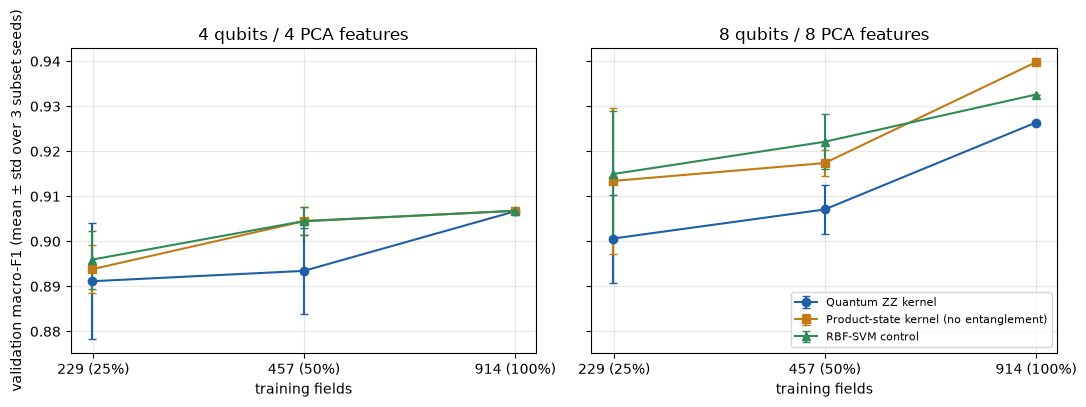

mean                     std             
fraction                  0.25    0.50    1.00    0.25    0.50 1.00
components model                                                   
4          product_z    0.8938  0.9045  0.9068  0.0054  0.0031  0.0
           quantum_zz   0.8911  0.8934  0.9067  0.0129  0.0095  0.0
           rbf_control  0.8959  0.9045  0.9068  0.0064  0.0031  0.0
8          product_z    0.9134  0.9174  0.9398  0.0162  0.0029  0.0
           quantum_zz   0.9006  0.9071  0.9264  0.0098  0.0055  0.0
           rbf_control  0.9149  0.9221  0.9326  0.0140  0.0061  0.0

In [3]:
names = {'quantum_zz': 'Quantum ZZ kernel', 'product_z': 'Product-state kernel (no entanglement)', 'rbf_control': 'RBF-SVM control'}
style = {'quantum_zz': ('#1f5fa8', 'o'), 'product_z': ('#c27a14', 's'), 'rbf_control': ('#2e8b57', '^')}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, n in zip(axes, (4, 8)):
    for m, (col, mk) in style.items():
        g = runs[(runs.components == n) & (runs.model == m)].groupby('fraction').macro_f1.agg(mean='mean', std=lambda x: x.std(ddof=0))
        ntr = (g.index.values * 914).round().astype(int)
        ax.errorbar(ntr, g['mean'], yerr=g['std'], marker=mk, color=col, capsize=3, label=names[m])
    ax.set(title=f'{n} qubits / {n} PCA features', xlabel='training fields', xscale='log', xticks=[229, 457, 914]); ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xticklabels(['229 (25%)', '457 (50%)', '914 (100%)']); ax.grid(alpha=.3)
axes[0].set_ylabel('validation macro-F1 (mean ± std over 3 subset seeds)'); axes[1].legend(fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig(FIG / 'learning_curve.png', dpi=160); plt.show()
tab = runs.groupby(['components', 'model', 'fraction']).macro_f1.agg(mean='mean', std=lambda x: x.std(ddof=0)).round(4).unstack('fraction')  # population std (ddof=0), as in the starter notebook
display(tab)

In [4]:
print('Paired spatial-block bootstrap on validation, full training set (quantum minus control, macro-F1):')
for k, b in R['bootstrap'].items():
    print(f"  {k:38s} mean {b['mean']:+.4f}   95% CI [{b['ci95'][0]:+.4f}, {b['ci95'][1]:+.4f}]")

Paired spatial-block bootstrap on validation, full training set (quantum minus control, macro-F1):
  pca4:quantum_zz-minus-rbf_control      mean +0.0004   95% CI [-0.0219, +0.0233]
  pca4:product_z-minus-rbf_control       mean +0.0000   95% CI [+0.0000, +0.0000]
  pca8:quantum_zz-minus-rbf_control      mean -0.0057   95% CI [-0.0356, +0.0268]
  pca8:product_z-minus-rbf_control       mean +0.0076   95% CI [-0.0168, +0.0368]


**Reading the sweep.** With a small tuned bandwidth the ZZ quantum kernel is **statistically indistinguishable from the RBF control** at both 4 and 8 qubits (all bootstrap intervals include 0), and it does **not** exceed the control. The non-entangling product-state kernel does about as well as the entangling ZZ kernel, so **entanglement is not what drives performance here**. At 25 % of the data the quantum kernels are slightly below the control at 8 qubits. Error bars come from only three random subsets; with 150 validation fields the differences between models are within selection noise.

## 2. Circuit depth and bandwidth: where does the quantum kernel work?

For the 8-qubit ZZ kernel we scan layers × bandwidth (best C per cell, full training set, validation macro-F1). This is the check behind the **selection rule** below.

122s | configs scoring >= 0.90: 33/144; best 0.9264; median 0.873


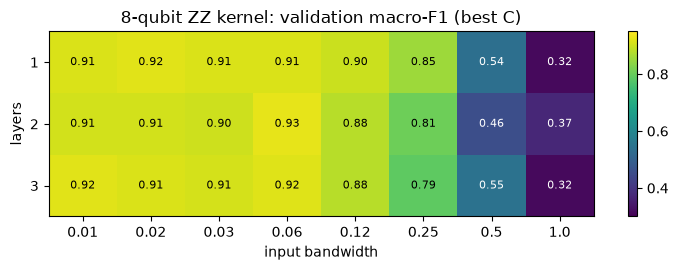

In [5]:
from kernel_vs_control import load_view, build_kernels, f1_of, SVC
v = load_view(8, tables); X = {'train': v['X_train'], 'validation': v['X_validation'], 'test': v['X_test']}
bws = [0.01, 0.02, 0.03, 0.06, 0.12, 0.25, 0.5, 1.0]; Cs = [0.3, 1, 3, 10, 30, 100]; grid = {}
t0 = time.perf_counter()
for reps in (1, 2, 3):
    for bw in bws:
        K, _ = build_kernels('quantum_zz', 8, reps, bw, X)
        for C in Cs:
            grid[(reps, bw, C)] = f1_of(v['y_validation'], SVC(kernel='precomputed', C=C).fit(K['train'], v['y_train']).predict(K['validation']))
H = np.array([[max(grid[(r, b, C)] for C in Cs) for b in bws] for r in (1, 2, 3)])
vals = np.array(list(grid.values()))
print(f'{time.perf_counter() - t0:.0f}s | configs scoring >= 0.90: {(vals >= .90).sum()}/{len(vals)}; best {vals.max():.4f}; median {np.median(vals):.3f}')
fig, ax = plt.subplots(figsize=(7.5, 2.8)); im = ax.imshow(H, vmin=0.3, vmax=0.95, cmap='viridis', aspect='auto')
for i in range(3):
    for j in range(len(bws)): ax.text(j, i, f'{H[i, j]:.2f}', ha='center', va='center', color='w' if H[i, j] < .7 else 'k', fontsize=8)
ax.set(xticks=range(len(bws)), xticklabels=bws, yticks=range(3), yticklabels=[1, 2, 3], xlabel='input bandwidth', ylabel='layers',
       title='8-qubit ZZ kernel: validation macro-F1 (best C)'); fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(FIG / 'bandwidth_layers.png', dpi=160); plt.show()

**Reading the scan.** At small bandwidths (0.01 to 0.06) **all three layer counts score about 0.90 to 0.93**, so extra layers bring no measurable gain; at large bandwidth (≥ 0.5, including the default scale of 1.0) the kernel collapses (macro-F1 between 0.32 and 0.55 for the 8-qubit kernel). A plausible reason is kernel concentration, where fidelities between different inputs become nearly identical as the circuit gets more expressive. We did not test that mechanism directly. The best bandwidths are small, where the kernel is smooth, which is consistent with, but does not prove, behaviour similar to a classical smooth kernel.

**Frozen selection rule (fixed before any test prediction, `configs/final_model.json`):** among the 144 validation trials, pick the *shallowest* circuit whose best validation macro-F1 is within 0.01 of the overall best. This gives **8 qubits, 1 layer, bandwidth 0.02, C = 100**, a cheaper circuit than the 2-layer maximum (0.926 vs 0.920, a difference well inside the noise). The control keeps its best-validation setting, which, if anything, slightly favours the control.

## 3. Final model vs. matched control vs. supplied reference (`experiments/final_evaluation.py`)

`challenge/submission.py` is the final model (`fit(X_train, y_train, seed)` / `predict(X)`): 13 raw features → StandardScaler → PCA(8) → StandardScaler (fitted on training rows) → 8-qubit ZZ fidelity kernel (1 layer) → SVM. The **matched control** uses the same preprocessing followed by an RBF-SVM; the **reference** is the supplied RBF-SVM on all 13 features. Seeds 0, 1, 2 are run for all three; all are deterministic, so the three results are identical.

In [6]:
t0 = time.perf_counter()
p = subprocess.run([sys.executable, 'experiments/final_evaluation.py'], cwd=ROOT, capture_output=True, text=True)
assert p.returncode == 0, p.stderr[-2000:]
print(f'final evaluation finished in {time.perf_counter() - t0:.0f}s')
F = json.loads((ROOT / 'outputs/final/final_results.json').read_text()); fr = pd.DataFrame(F['runs'])
rows = []
for m, g in fr.groupby('model', sort=False):
    rows.append({'model': m, 'macro-F1 mean': g.macro_f1.mean(), 'macro-F1 std': g.macro_f1.std(ddof=0), 'accuracy': g.accuracy.mean(),
                 'preproc s': g.preprocessing_seconds.mean(), 'fit s': g.fit_seconds.mean(), 'predict s': g.predict_seconds.mean()})
display(pd.DataFrame(rows).round(4).set_index('model'))

final evaluation finished in 94s


,macro-F1 mean,macro-F1 std,accuracy,preproc s,fit s,predict s
model,,,,,,
quantum_kernel (final),0.9201,0.0,0.9200,0.0230,1.7950,0.3758
matched_rbf_control,0.9326,0.0,0.9333,0.0037,0.0156,0.0036
reference_rbf_svm,0.8797,0.0,0.8800,0.0000,0.0215,0.0048


precision                recall            
class                    alfalfa  maize  wheat alfalfa maize wheat
model                                                             
matched_rbf_control        0.941  0.925  0.935    0.96  0.98  0.86
quantum_kernel (final)     0.940  0.939  0.882    0.94  0.92  0.90
reference_rbf_svm          0.887  0.915  0.840    0.94  0.86  0.84

,qubits,layers,depth,two_qubit_gates,trainable_quantum_params,frozen_quantum_params,readout_trainable_params,support_vectors,statevector_simulations,pairwise_fidelity_circuits_equiv
quantum_kernel (final),8.0,1.0,23.0,14.0,0.0,1.0,445.0,221.0,1135.0,619235.0
matched_rbf_control,0.0,NaN,NaN,NaN,0.0,NaN,405.0,201.0,NaN,NaN
reference_rbf_svm,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN


Bootstrap, quantum minus other (validation macro-F1, spatial blocks):
  vs matched_rbf_control    mean -0.0118   95% CI [-0.0466, +0.0277]
  vs reference_rbf_svm      mean +0.0422   95% CI [-0.0006, +0.0953]


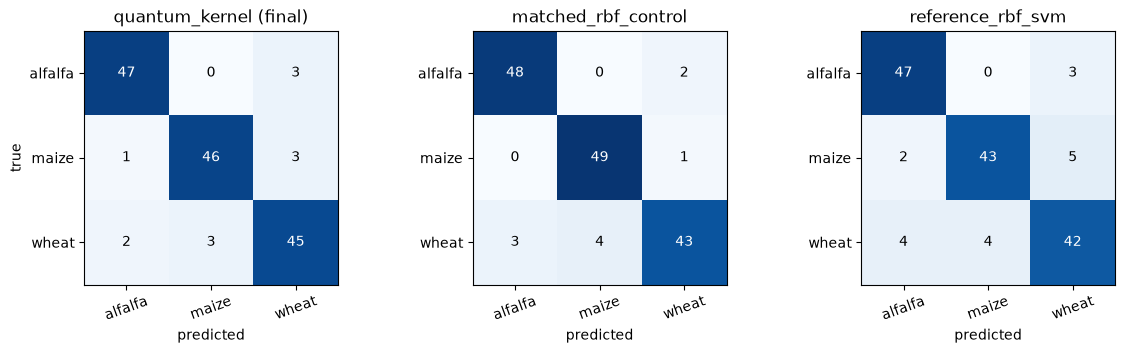

In [7]:
cls = pd.DataFrame([{'model': r.model, 'class': c, 'precision': r.precision[i], 'recall': r.recall[i]}
                    for r in fr[fr.seed == 0].itertuples() for i, c in enumerate(LABELS)])
display(cls.pivot(index='model', columns='class', values=['precision', 'recall']).round(3))
res = pd.DataFrame({r.model: r.resources for r in fr[fr.seed == 0].itertuples()}).T
display(res)
print('Bootstrap, quantum minus other (validation macro-F1, spatial blocks):')
for k, b in F['bootstrap_quantum_minus'].items(): print(f"  vs {k:22s} mean {b['mean']:+.4f}   95% CI [{b['ci95'][0]:+.4f}, {b['ci95'][1]:+.4f}]")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, r in zip(axes, fr[fr.seed == 0].itertuples()):
    cm = np.array(r.confusion); nm = cm / cm.sum(1, keepdims=True); ax.imshow(nm, vmin=0, vmax=1, cmap='Blues')
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', color='w' if nm[i, j] > .55 else 'k')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS, xlabel='predicted', title=r.model, ylabel='true' if ax is axes[0] else '')
    ax.tick_params(axis='x', labelrotation=20)
fig.tight_layout(); fig.savefig(FIG / 'confusion.png', dpi=160); plt.show()

## 4. Findings, limitations, reproducibility

**What the experiments support**
1. A tuned fidelity quantum kernel on 8 PCA features reaches validation macro-F1 ≈ 0.92, **about 4 points above the supplied 13-feature reference (0.88)**, but the **matched classical control reaches the same or slightly higher (0.93)**. The quantum-minus-control bootstrap interval includes 0, so we find **no measurable quantum contribution** on this task. The improvement over the reference is shared by the control and therefore comes from compressing to 8 PCA features, not from the quantum circuit.
2. **Depth:** on the small-bandwidth plateau, 1 layer scores as well as 2 or 3 layers at lower circuit cost (depth 23 vs. more) in this data, which is what the final model uses.
3. **Entanglement:** a non-entangling product-state kernel scores about the same as the entangling ZZ kernel.
4. **Bandwidth is critical:** the default input scale makes the 8-qubit kernel fail; shrinking the bandwidth by 1 to 2 orders of magnitude fixes it.
5. **Low data:** quantum kernels sit slightly below the control at 25 % of training fields (8 qubits); differences at 50 % and 100 % are within noise.

**Not claimed:** any quantum advantage, any speed-up, anything about noisy devices, larger datasets, other regions or other dates.

**Limitations**
- Exact simulation only. The reported circuit evaluations are statevector simulations; the "pairwise fidelity circuits equivalent" figure is the count a sampling-based kernel would need, not something we executed. Kernel cost grows with the square of the training set.
- Validation (150 fields) selected hyperparameters and scores the comparison; with 144 trials per model, selection noise is large relative to the gaps between models. Test labels do not exist locally, so the final test macro-F1 is unknown.
- The PCA views were fitted on the full training set; the 25 % / 50 % runs subsample labelled rows but reuse that training-fitted projection (no validation or test data involved).
- Labels from 23 to 27 April 2024 are assumed valid for imagery from 25 April ± 2 days; crop persistence was not independently verified. One region and one acquisition date.
- Tuning effort is matched in trial count (144 each), not in compute time; the two quantum models and the control differ in the parameters they tune.

**Reproducibility.** Python 3.12 with the pinned `requirements.txt`; all quantum results are deterministic (no sampling), so seeds 0, 1, 2 coincide for the full training set; the 25 % / 50 % rows differ by seed through the chosen training subset. Frozen model settings: `configs/final_model.json`. Final model: `challenge/submission.py`. Outputs: `outputs/final/` (summary, validation predictions, **test predictions**), `outputs/kernel_vs_control/`, `outputs/figures/`.

**References and reused code.** Supplied repository helpers (data loading and checks, `challenge.metrics`, reference RBF-SVM, validation groups) from the challenge repository; Qiskit 2.4.2 (`Statevector`, `zz_feature_map`, `z_feature_map`); scikit-learn (`SVC`, PCA). ZZ feature map and quantum kernels: Havlíček et al., *Nature* 567, 209 (2019). Kernel bandwidth: Shaydulin and Wild, *Phys. Rev. A* 106, 042407 (2022). Power of data / kernel comparison with classical kernels: Huang et al., *Nat. Commun.* 12, 2631 (2021). Dataset: Ouassanouan et al., *Scientific Data* 13, 746 (2026), doi:10.1038/s41597-026-06993-y (CC BY-NC-ND 4.0).

**Optional, not run here:** inference-only IBM hardware demo (`challenge/hardware.py`, token via `QISKIT_IBM_TOKEN`). No hardware result is reported in this notebook.

In [8]:
tp = pd.read_csv(ROOT / 'outputs/final/test_predictions_quantum_kernel.csv')
assert tp.shape == (221, 2) and tp.sample_id.is_unique and set(tp.prediction) <= set(LABELS)
assert set(tp.sample_id) == set(tables['test'].sample_id)
print('Test predictions written (no test labels exist, so no test score is computed):')
print(tp.shape, tp.prediction.value_counts().to_dict())

Test predictions written (no test labels exist, so no test score is computed):
(221, 2) {'wheat': 100, 'maize': 72, 'alfalfa': 49}
